<h1>TPE Fundamentos de la Ciencia de Datos</h1>

<h3>GRUPO 2:</h3>
<ul>
<li>Joan Martin Lenti</li>
<li>Valentina Bianchi</li>
<li>Manuel Taboada</li>
</ul>
<h3>Data set: Encuesta Nacional de Factores de Riesgo 2018</h3>

<h1>Índice</h1>
<p><a href="#1"><b>1.</b> Instalación de librerias</a></p>
<p style="margin-left: 20px;"><a href="#1.1"><b>1.1.</b> Incorporación de librerias utilizadas</a></p>
<p><a href="#2"><b>2.</b> Inclusión del Dataset</a></p>
<p style="margin-left: 20px;"><a href="#2.1"><b>2.1.</b> Creación de Dataframes que utilizamos</a></p>
<p style="margin-left: 20px;"><a href="#2.2"><b>2.2.</b> Dataframes</a></p>
<p style="margin-left: 40px;"><a href="#2.2.1"><b>2.2.1.</b> Dataframe Hipertensión</a></p>
<p style="margin-left: 40px;"><a href="#2.2.2"><b>2.2.2.</b> Dataframe Alimentación</a></p>
<p style="margin-left: 40px;"><a href="#2.2.3"><b>2.2.3.</b> Dataframe Colesterol</a></p>
<p style="margin-left: 40px;"><a href="#2.2.4"><b>2.2.4.</b> Dataframe Hipótesis</a></p>
<p><a href="#3"><b>3.</b> Instalación de librerias</a></p>

<a id="1"></a><h2>1. Instalacion de librerias</h2>

In [32]:
!pip install wget
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install scipy

<a id="1.1"></a><h3>1.1. Incorporación de librerias utilizadas</h3>

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import wget
import os

<a id="2"></a><h2>2. Inclusión del Dataset</h2>

In [34]:
url = "https://raw.githubusercontent.com/Acaide04/Analisis_ENFR_2018/refs/heads/ENFR2018/ENFR%202018%20-%20Base%20usuario.txt"


df = pd.read_csv(url, sep="|")
df_original = df


df = df.drop_duplicates()
df = df.replace([98, 99, 999, 9999], pd.NA)
df = df.replace(r'^\s*$', pd.NA, regex=True) 
df = df.drop(columns=[col for col in df.columns if col.endswith("99")])

<a id="2.1"></a><h3>2.1. Creación de Dataframes que utilizamos</h3>

In [35]:
columnas_ha = [
    col for col in df.columns
    if "biha" in col or col in ["control_hipertension","prevalencia_hipertension"]
]

columnas_al = [
    col for col in df.columns
    if "bial" in col or col in ["promedio_fv_diario", "consumo_fv", "barreras_fyv", "tipo_dieta_razones"]
]

columnas_co = [
    col for col in df.columns
    if "bico" in col or col in ["control_colesterol", "prevalencia_colesterol"]
]

df_HA = df[columnas_ha].copy()
df_AL = df[columnas_al].copy()
df_CO = df[columnas_co].copy()

df_HIPOTESIS = df[['bial03', 'bial04', 'bial05', 'bial06', 'nivel_actividad_fisica', 'imc_bima','promedio_sistolica', 'bima13', 'bhch04', 'bimq05']].copy()

<a id="2.2"></a><h3>2.2. Dataframes</h3>

<a id="2.2.1"></a><h4>2.2.1 Dataframe Hipertención</h4>

In [36]:
for columna in df_HA:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_HA[columna].dtype)
        print("Nulos:", df_HA[columna].isna().sum())
        print("Valores:", df_HA[columna].value_counts())
        print("NoNulos", df_HA[columna].notna().sum())

df_HA.describe()

df_HA = df_HA.dropna(how="all")


--- biha01 ---
Tipo: object
Nulos: 83
Valores: biha01
1    27142
2     1999
Name: count, dtype: int64
NoNulos 29141

--- biha02 ---
Tipo: object
Nulos: 2275
Valores: biha02
1.0    21561
2.0     3242
3.0     2146
Name: count, dtype: int64
NoNulos 26949

--- biha03 ---
Tipo: object
Nulos: 212
Valores: biha03
3    18579
2     6755
1     3678
Name: count, dtype: int64
NoNulos 29012

--- biha04 ---
Tipo: float64
Nulos: 18791
Valores: biha04
1.0    5713
2.0    4720
Name: count, dtype: int64
NoNulos 10433

--- biha05_01 ---
Tipo: float64
Nulos: 23511
Valores: biha05_01
1.0    2934
2.0    2779
Name: count, dtype: int64
NoNulos 5713

--- biha05_02 ---
Tipo: float64
Nulos: 23511
Valores: biha05_02
1.0    5238
2.0     475
Name: count, dtype: int64
NoNulos 5713

--- biha06 ---
Tipo: float64
Nulos: 24009
Valores: biha06
1.0     3172
2.0     1576
3.0      256
4.0      169
5.0       18
6.0       12
8.0        5
10.0       4
7.0        2
13.0       1
Name: count, dtype: int64
NoNulos 5215

--- biha07

<a id="2.2.2"></a><h4>2.2.2 Dataframe Alimentación</h4>

In [37]:
for columna in df_AL:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_AL[columna].dtype)
        print("Nulos:", df_AL[columna].isna().sum())
        print("Valores:", df_AL[columna].value_counts())
        print("NoNulos", df_AL[columna].notna().sum())

df_AL.describe()


df_AL = df_AL.dropna(how="all")


--- bial01 ---
Tipo: object
Nulos: 98
Valores: bial01
1    20780
2     8346
Name: count, dtype: int64
NoNulos 29126

--- bial02 ---
Tipo: int64
Nulos: 0
Valores: bial02
3    18583
2     6825
1     3816
Name: count, dtype: int64
NoNulos 29224

--- bial03 ---
Tipo: float64
Nulos: 571
Valores: bial03
7.0    9549
3.0    4262
2.0    3969
1.0    2916
0.0    2568
5.0    2506
4.0    1953
6.0     930
Name: count, dtype: int64
NoNulos 28653

--- bial04 ---
Tipo: float64
Nulos: 3018
Valores: bial04
1.0     14532
2.0      7582
3.0      2396
4.0       778
5.0       365
7.0       177
6.0       158
10.0       47
1.5        39
8.0        33
0.5        31
2.5        20
12.0       14
9.0        11
15.0        8
13.0        4
1.2         4
4.5         2
14.0        2
11.0        1
17.0        1
2.2         1
Name: count, dtype: int64
NoNulos 26206

--- bial05 ---
Tipo: float64
Nulos: 287
Valores: bial05
7.0    10176
3.0     4788
5.0     3719
2.0     3238
4.0     3019
1.0     1582
6.0     1510
0.0      9

<a id="2.2.3"></a><h4>2.2.3 Dataframe Colesterol</h4>

In [38]:
for columna in df_CO:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_CO[columna].dtype)
        print("Nulos:", df_CO[columna].isna().sum())
        print("Valores:", df_CO[columna].value_counts())
        print("NoNulos", df_CO[columna].notna().sum())

df_CO.describe()


df_CO = df_CO.dropna(how="all")


--- bico01 ---
Tipo: object
Nulos: 376
Valores: bico01
1    20576
2     8272
Name: count, dtype: int64
NoNulos 28848

--- bico02 ---
Tipo: object
Nulos: 8812
Valores: bico02
1.0    14568
2.0     3649
3.0     2195
Name: count, dtype: int64
NoNulos 20412

--- bico03 ---
Tipo: object
Nulos: 419
Valores: bico03
2    22422
1     6383
Name: count, dtype: int64
NoNulos 28805

--- bico04 ---
Tipo: float64
Nulos: 22841
Valores: bico04
2.0    3373
1.0    3010
Name: count, dtype: int64
NoNulos 6383

--- bico05_01 ---
Tipo: float64
Nulos: 26214
Valores: bico05_01
1.0    1976
2.0    1034
Name: count, dtype: int64
NoNulos 3010

--- bico05_02 ---
Tipo: float64
Nulos: 26214
Valores: bico05_02
1.0    2182
2.0     828
Name: count, dtype: int64
NoNulos 3010

--- control_colesterol ---
Tipo: object
Nulos: 12413
Valores: control_colesterol
1.0    13830
2.0     2981
Name: count, dtype: int64
NoNulos 16811

--- prevalencia_colesterol ---
Tipo: object
Nulos: 8785
Valores: prevalencia_colesterol
2.0    14150


<a id="2.2.4"></a><h4>2.2.4 Dataframe Hipótesis</h4>

In [39]:
for columna in df_HIPOTESIS:
        print(f"\n--- {columna} ---")
        print("Tipo:", df_HIPOTESIS[columna].dtype)
        print("Nulos:", df_HIPOTESIS[columna].isna().sum())
        print("Valores:", df_HIPOTESIS[columna].value_counts())
        print("NoNulos", df_HIPOTESIS[columna].notna().sum())

df_HIPOTESIS.describe()


df_HIPOTESIS = df_HIPOTESIS.dropna(how="all")


--- bial03 ---
Tipo: float64
Nulos: 571
Valores: bial03
7.0    9549
3.0    4262
2.0    3969
1.0    2916
0.0    2568
5.0    2506
4.0    1953
6.0     930
Name: count, dtype: int64
NoNulos 28653

--- bial04 ---
Tipo: float64
Nulos: 3018
Valores: bial04
1.0     14532
2.0      7582
3.0      2396
4.0       778
5.0       365
7.0       177
6.0       158
10.0       47
1.5        39
8.0        33
0.5        31
2.5        20
12.0       14
9.0        11
15.0        8
13.0        4
1.2         4
4.5         2
14.0        2
11.0        1
17.0        1
2.2         1
Name: count, dtype: int64
NoNulos 26206

--- bial05 ---
Tipo: float64
Nulos: 287
Valores: bial05
7.0    10176
3.0     4788
5.0     3719
2.0     3238
4.0     3019
1.0     1582
6.0     1510
0.0      905
Name: count, dtype: int64
NoNulos 28937

--- bial06 ---
Tipo: float64
Nulos: 1164
Valores: bial06
1.00     18354
2.00      6616
3.00       990
0.50       768
4.00       400
1.50       334
5.00       204
7.00       172
6.00        94
2.50   

<a href="3"></a><h2>3. Hipótesis</h2>

<a href="3.1"></a><h3>3.1 Hipótesis Univariada</h3>
<h4>Más de la mitad de los hipertensos que toman medicación se olvida alguna vez de tomarla</h4>
<h5>H0: La mitad o menos se olvida</h5>
<h5>H1: Más de la mitad se olvida   |   alpha = 0.05</h5>

<a href="3.1.1"></a><h4>3.1.1 Exploración del dataframe</h4>

In [40]:
print("Valores de biha07 (incluye nulos):")
print(df_HA['biha07'].value_counts(dropna=False))
print("\nTabla cruzada tratamiento con medicamentos (biha05_02) vs olvido (biha07)")
print("(0 = no corresponde la pregunta)")
print(pd.crosstab(df_HA['biha05_02'].fillna(0), df_HA['biha07'].fillna(0)))

Valores de biha07 (incluye nulos):
biha07
NaN    23961
2.0     3850
1.0     1388
Name: count, dtype: int64

Tabla cruzada tratamiento con medicamentos (biha05_02) vs olvido (biha07)
(0 = no corresponde la pregunta)
biha07       0.0   1.0   2.0
biha05_02                   
0.0        23486     0     0
1.0            0  1388  3850
2.0          475     0     0


<a href="3.1.2"></a><h4>3.1.2 Población de estudio</h4>

In [41]:
med = df_HA[df_HA['biha05_02'] == 1].copy()
for col in ['biha07', 'biha08', 'biha09']:
    med[col] = pd.to_numeric(med[col], errors='coerce')

print("\nHipertensos medicados:", len(med))
print("Nulos en biha07:", med['biha07'].isna().sum())
med['olvida'] = med['biha07'].map({1: 'Sí', 2: 'No'})


Hipertensos medicados: 5238
Nulos en biha07: 0


<a href="3.1.3"></a><h4>3.1.3 Tablas de frecuencias <h4>

In [42]:
frec = pd.DataFrame({
    'Frecuencia': med['olvida'].value_counts(),
    'Porcentaje': med['olvida'].value_counts(normalize=True) * 100
})
print("\nTabla de frecuencias:")
print(frec.round(2))


Tabla de frecuencias:
        Frecuencia  Porcentaje
olvida                        
No            3850        73.5
Sí            1388        26.5


<a href="3.1.4"></a><h4>3.1.4 Gráfico de barras <h4>

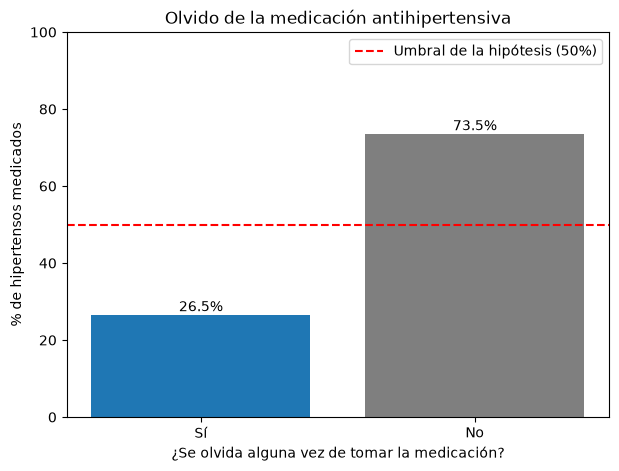

In [43]:
porcentajes = med['olvida'].value_counts(normalize=True)[['Sí', 'No']] * 100

plt.figure(figsize=(7, 5))
plt.bar(porcentajes.index, porcentajes.values, color=['tab:blue', 'tab:gray'])
plt.axhline(50, color='red', linestyle='--', label='Umbral de la hipótesis (50%)')
for i, v in enumerate(porcentajes.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylim(0, 100)
plt.xlabel('¿Se olvida alguna vez de tomar la medicación?')
plt.ylabel('% de hipertensos medicados')
plt.title('Olvido de la medicación antihipertensiva')
plt.legend()
plt.show()

<a href="3.1.5"></a><h4>3.1.5 Variables para tests y verficación de supuestos <h4>

In [44]:
n = len(med)
x = int((med['olvida'] == 'Sí').sum())
p_hat = x / n
p0 = 0.5
alpha = 0.05
print("\nSupuesto de aproximación normal: n·p0 =", n * p0, "| n·(1-p0) =", n * (1 - p0))


Supuesto de aproximación normal: n·p0 = 2619.0 | n·(1-p0) = 2619.0


<a href="3.1.6"></a><h4>3.1.6 Test Z<h4>

In [45]:
z = (p_hat - p0) / np.sqrt(p0 * (1 - p0) / n)
p_valor = stats.norm.sf(z)   # cola derecha: H1 es p > 0.5
print("\n[Test z] p̂ = %.4f | z = %.2f | p-valor = %.4f" % (p_hat, z, p_valor))
if p_valor < alpha:
    print("Se rechaza H0: más de la mitad se olvida")
else:
    print("No se rechaza H0: no hay evidencia de que más de la mitad se olvide")



[Test z] p̂ = 0.2650 | z = -34.02 | p-valor = 1.0000
No se rechaza H0: no hay evidencia de que más de la mitad se olvide


<a href="3.1.7"></a><h4>3.1.7 Test binomial<h4>

In [46]:
res = stats.binomtest(x, n, p=p0, alternative='greater')
print("\n[Binomial exacto] p-valor = %.4f" % res.pvalue)
print("Se rechaza H0" if res.pvalue < alpha else "No se rechaza H0")



[Binomial exacto] p-valor = 1.0000
No se rechaza H0


<a href="3.1.8"></a><h4>3.1.8 Test de Wilson<h4>


IC 95%: [25.32%, 27.71%]


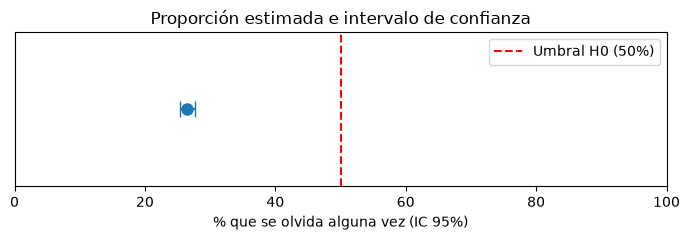

In [47]:
ic = stats.binomtest(x, n).proportion_ci(confidence_level=0.95, method='wilson')
print("\nIC 95%%: [%.2f%%, %.2f%%]" % (ic.low * 100, ic.high * 100))

plt.figure(figsize=(7, 2.5))
plt.errorbar(p_hat * 100, 0, xerr=[[(p_hat - ic.low) * 100], [(ic.high - p_hat) * 100]],
             fmt='o', capsize=6, markersize=8)
plt.axvline(50, color='red', linestyle='--', label='Umbral H0 (50%)')
plt.xlim(0, 100)
plt.yticks([])
plt.xlabel('% que se olvida alguna vez (IC 95%)')
plt.title('Proporción estimada e intervalo de confianza')
plt.legend()
plt.tight_layout()
plt.show()

<a href="3.1.9"></a><h4>3.1.9 Indicador de Morisky-Greenn<h4>


Análisis de sensibilidad:
                                    n       %  IC inf  IC sup  p-valor
Indicador                                                             
Se olvida (biha07)               5238  26.499  25.321  27.711      1.0
Deja si se siente bien (biha08)  5229  11.589  10.750  12.485      1.0
Deja si se siente mal (biha09)   5224   5.188   4.618   5.823      1.0
No adherente (Morisky-Green)     5225  31.943  30.692  33.220      1.0


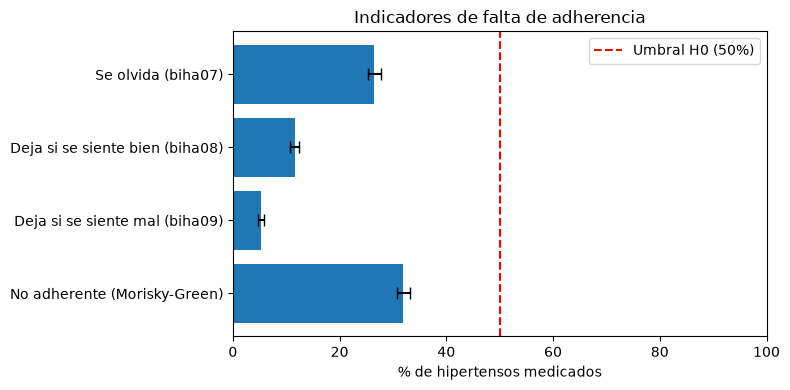

In [48]:

items = med[['biha07', 'biha08', 'biha09']]
med['no_adherente'] = np.where((items == 1).any(axis=1), 1,
                       np.where(items.notna().all(axis=1), 0, np.nan))

indicadores = {
    'Se olvida (biha07)': med['biha07'].map({1: 1, 2: 0}),
    'Deja si se siente bien (biha08)': med['biha08'].map({1: 1, 2: 0}),
    'Deja si se siente mal (biha09)': med['biha09'].map({1: 1, 2: 0}),
    'No adherente (Morisky-Green)': med['no_adherente'],
}
filas = []
for nombre, serie in indicadores.items():
    s = serie.dropna()
    k = int(s.sum())
    r = stats.binomtest(k, len(s), p=p0, alternative='greater')
    ic_i = stats.binomtest(k, len(s)).proportion_ci(method='wilson')
    filas.append({'Indicador': nombre, 'n': len(s), '%': 100 * k / len(s),
                  'IC inf': 100 * ic_i.low, 'IC sup': 100 * ic_i.high, 'p-valor': r.pvalue})
sens = pd.DataFrame(filas).set_index('Indicador')
print("\nAnálisis de sensibilidad:")
print(sens.round(3))

plt.figure(figsize=(8, 4))
plt.barh(sens.index, sens['%'], color='tab:blue',
         xerr=[sens['%'] - sens['IC inf'], sens['IC sup'] - sens['%']], capsize=4)
plt.gca().invert_yaxis()
plt.axvline(50, color='red', linestyle='--', label='Umbral H0 (50%)')
plt.xlim(0, 100)
plt.xlabel('% de hipertensos medicados')
plt.title('Indicadores de falta de adherencia')
plt.legend()
plt.tight_layout()
plt.show()

<a href="3.2"></a><h3>3.2 Hipótesis Bivariada</h3>
<h4>Quienes agregan sal con más frecuencia a la comida cocida tienen mayor prevalencia de hipertensión</h4>
<h5>H0: la prevalencia de hipertensión es independiente de la frecuencia de uso de sal</h5>
<h5>H1: existe asociación entre ambas   |   alpha = 0.05</h5>

<a href="3.2.1"></a><h4>3.2.1 Exploración de las variables</h4>

In [49]:
print("bial02 (1 = siempre/casi siempre, 2 = raras veces, 3 = nunca):")
print(df['bial02'].value_counts(dropna=False))
print("\nprevalencia_hipertension (1 = Sí, 2 = No):")
print(df['prevalencia_hipertension'].value_counts(dropna=False))

bial02 (1 = siempre/casi siempre, 2 = raras veces, 3 = nunca):
bial02
3    18583
2     6825
1     3816
Name: count, dtype: int64

prevalencia_hipertension (1 = Sí, 2 = No):
prevalencia_hipertension
2.0     16731
1.0     10258
NaN      2082
<NA>      153
Name: count, dtype: int64


<a href="3.2.2"></a><h4>3.2.2 Creación del dataframe</h4>

In [50]:
biv = df[['bial02', 'prevalencia_hipertension', 'rango_edad']].apply(pd.to_numeric, errors='coerce').dropna()
orden_sal = ['Siempre/casi siempre', 'Raras veces', 'Nunca']
biv['sal'] = pd.Categorical(biv['bial02'].map({1: 'Siempre/casi siempre', 2: 'Raras veces', 3: 'Nunca'}),
                            categories=orden_sal, ordered=True)
biv['hta'] = biv['prevalencia_hipertension'].map({1: 'Sí', 2: 'No'})
print("\nCasos válidos:", len(biv))


Casos válidos: 26989


<a href="3.2.3"></a><h4>3.2.3 Tabla de contingencia</h4>

In [51]:
tabla = pd.crosstab(biv['sal'], biv['hta'])[['Sí', 'No']]
print("\nTabla de contingencia (frecuencias absolutas):")
print(tabla)
print("\nPrevalencia de hipertensión por categoría (% por fila):")
print((pd.crosstab(biv['sal'], biv['hta'], normalize='index')[['Sí', 'No']] * 100).round(1))


Tabla de contingencia (frecuencias absolutas):
hta                     Sí     No
sal                              
Siempre/casi siempre  1037   2364
Raras veces           2047   4150
Nunca                 7174  10217

Prevalencia de hipertensión por categoría (% por fila):
hta                     Sí    No
sal                             
Siempre/casi siempre  30.5  69.5
Raras veces           33.0  67.0
Nunca                 41.3  58.7


<a href="3.2.4"></a><h4>3.2.4 Gráfico de prevalencia por categoría</h4>

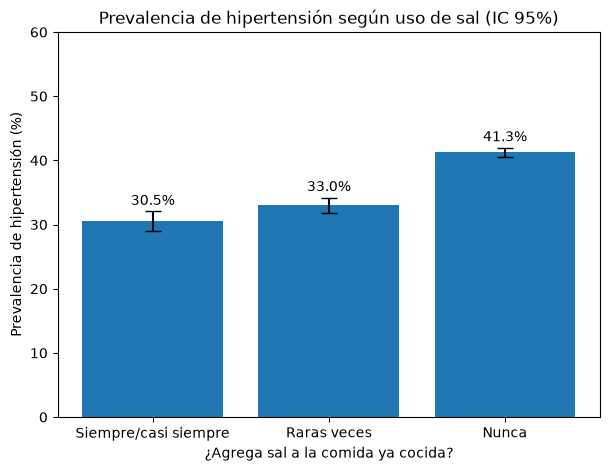

In [52]:
prev, ic_inf, ic_sup = [], [], []
for cat in orden_sal:
    k = int(tabla.loc[cat, 'Sí'])
    m = int(tabla.loc[cat].sum())
    ic = stats.binomtest(k, m).proportion_ci(method='wilson')
    prev.append(100 * k / m)
    ic_inf.append(100 * ic.low)
    ic_sup.append(100 * ic.high)
prev, ic_inf, ic_sup = np.array(prev), np.array(ic_inf), np.array(ic_sup)

plt.figure(figsize=(7, 5))
plt.bar(orden_sal, prev, color='tab:blue', yerr=[prev - ic_inf, ic_sup - prev], capsize=6)
for i, v in enumerate(prev):
    plt.text(i, ic_sup[i] + 1, f'{v:.1f}%', ha='center')
plt.ylim(0, 60)
plt.xlabel('¿Agrega sal a la comida ya cocida?')
plt.ylabel('Prevalencia de hipertensión (%)')
plt.title('Prevalencia de hipertensión según uso de sal (IC 95%)')
plt.show()

<a href="3.2.5"></a><h4>3.2.5 Chi-cuadrado de independencia</h4>

In [53]:
chi2, p_valor, gl, esperadas = stats.chi2_contingency(tabla)
print("\nFrecuencias esperadas bajo H0:")
print(pd.DataFrame(esperadas, index=tabla.index, columns=tabla.columns).round(1))
print("Mínima frecuencia esperada:", round(esperadas.min(), 1), "(supuesto: todas >= 5)")

print("\n[Chi-cuadrado] χ² = %.2f | gl = %d | p-valor = %.4g" % (chi2, gl, p_valor))
if p_valor < 0.05:
    print("Se rechaza H0: existe asociación entre uso de sal e hipertensión")
else:
    print("No se rechaza H0: no hay evidencia de asociación")


Frecuencias esperadas bajo H0:
hta                       Sí       No
sal                                  
Siempre/casi siempre  1292.7   2108.3
Raras veces           2355.4   3841.6
Nunca                 6610.0  10781.0
Mínima frecuencia esperada: 1292.7 (supuesto: todas >= 5)

[Chi-cuadrado] χ² = 224.32 | gl = 2 | p-valor = 1.951e-49
Se rechaza H0: existe asociación entre uso de sal e hipertensión


<a href="3.2.6"></a><h4>3.2.6 V de Cramér</h4>

In [54]:
n = tabla.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
print("\nV de Cramér = %.3f" % v_cramer)
print("Interpretación: < 0.1 muy débil | 0.1-0.3 débil | 0.3-0.5 moderada | > 0.5 fuerte")


V de Cramér = 0.091
Interpretación: < 0.1 muy débil | 0.1-0.3 débil | 0.3-0.5 moderada | > 0.5 fuerte


<a href="3.2.7"></a><h4>3.2.7 Residuos estandarizados ajustados</h4>


Residuos estandarizados ajustados (|r| > 1.96 = celda significativa):
hta                      Sí     No
sal                               
Siempre/casi siempre  -9.66   9.66
Raras veces           -9.19   9.19
Nunca                 14.77 -14.77


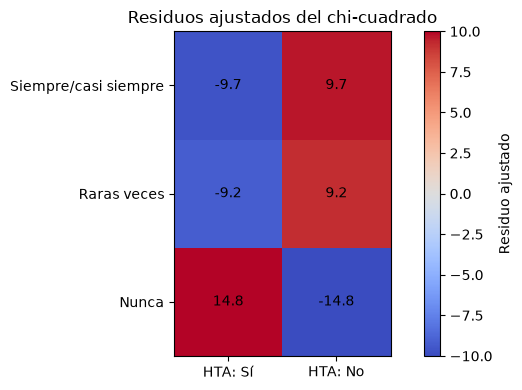

In [55]:
fila = tabla.sum(axis=1).values[:, None] / n
col = tabla.sum(axis=0).values[None, :] / n
residuos = (tabla.values - esperadas) / np.sqrt(esperadas * (1 - fila) * (1 - col))
residuos = pd.DataFrame(residuos, index=tabla.index, columns=tabla.columns)
print("\nResiduos estandarizados ajustados (|r| > 1.96 = celda significativa):")
print(residuos.round(2))

plt.figure(figsize=(7, 4))
plt.imshow(residuos.values, cmap='coolwarm', vmin=-10, vmax=10)
plt.colorbar(label='Residuo ajustado')
plt.xticks([0, 1], ['HTA: Sí', 'HTA: No'])
plt.yticks(range(3), orden_sal)
for i in range(3):
    for j in range(2):
        plt.text(j, i, f'{residuos.values[i, j]:.1f}', ha='center', va='center')
plt.title('Residuos ajustados del chi-cuadrado')
plt.tight_layout()
plt.show()

<a href="3.2.8"></a><h4>3.2.8 Test Z para dos proporciones</h4>

In [56]:
k1, n1 = tabla.loc['Siempre/casi siempre', 'Sí'], tabla.loc['Siempre/casi siempre'].sum()
k2, n2 = tabla.loc['Nunca', 'Sí'], tabla.loc['Nunca'].sum()
p1, p2 = k1 / n1, k2 / n2
p_pool = (k1 + k2) / (n1 + n2)
z = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_valor_z = stats.norm.sf(z)
print("\n[Test z dos proporciones] Siempre: %.1f%% | Nunca: %.1f%%" % (100 * p1, 100 * p2))
print("z = %.2f | p-valor (H1: siempre > nunca) = %.4f" % (z, p_valor_z))
if p_valor_z < 0.05:
    print("Se rechaza H0: quienes agregan sal siempre tienen mayor prevalencia")
else:
    print("No se rechaza H0: quienes agregan sal siempre NO tienen mayor prevalencia")



[Test z dos proporciones] Siempre: 30.5% | Nunca: 41.3%
z = -11.74 | p-valor (H1: siempre > nunca) = 1.0000
No se rechaza H0: quienes agregan sal siempre NO tienen mayor prevalencia


<a href="3.2.9"></a><h4>3.2.9 Control por edad</h4>


% que agrega sal siempre/casi siempre por grupo de edad:
sal         Siempre/casi siempre  Raras veces  Nunca
rango_edad                                          
18-24                       17.7         27.1   55.2
25-34                       17.1         23.2   59.7
35-49                       14.2         23.1   62.8
50-64                        9.7         21.9   68.4
65+                          7.2         21.7   71.1

Prevalencia de hipertensión (%) por edad y uso de sal:
sal         Siempre/casi siempre  Raras veces  Nunca
rango_edad                                          
18-24                       20.6         14.0   16.9
25-34                       22.0         19.6   21.6
35-49                       26.6         25.8   31.4
50-64                       40.9         42.3   52.0
65+                         55.1         57.5   65.5


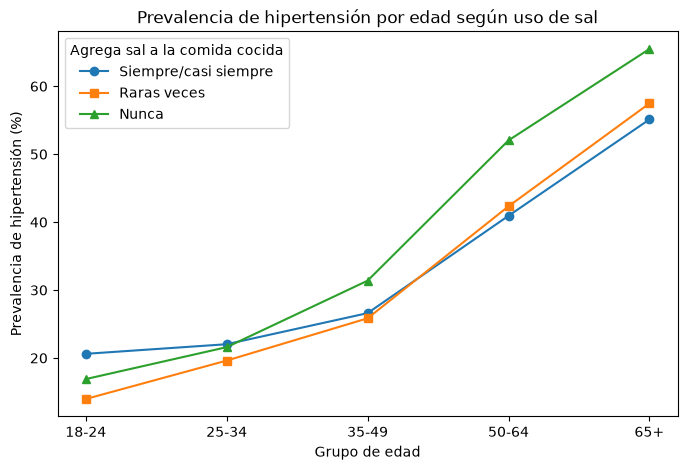

In [57]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

etq_edad = {1: '18-24', 2: '25-34', 3: '35-49', 4: '50-64', 5: '65+'}
print("\n% que agrega sal siempre/casi siempre por grupo de edad:")
print((pd.crosstab(biv['rango_edad'].map(etq_edad), biv['sal'], normalize='index') * 100).round(1))

prev_edad = pd.crosstab([biv['rango_edad'].map(etq_edad), biv['sal']], biv['hta'],
                        normalize='index')['Sí'].unstack() * 100
print("\nPrevalencia de hipertensión (%) por edad y uso de sal:")
print(prev_edad.round(1))

plt.figure(figsize=(8, 5))
for cat, marcador in zip(orden_sal, ['o', 's', '^']):
    plt.plot(prev_edad.index, prev_edad[cat], marker=marcador, label=cat)
plt.xlabel('Grupo de edad')
plt.ylabel('Prevalencia de hipertensión (%)')
plt.title('Prevalencia de hipertensión por edad según uso de sal')
plt.legend(title='Agrega sal a la comida cocida')
plt.show()

In [58]:
# ============================================================
# HIPÓTESIS MULTIVARIADA
# "La probabilidad de colesterol elevado es mayor en quienes consumen
#  menos frutas y verduras y consideran poco saludable su alimentación"
# H0: los coeficientes de ambas variables son iguales a cero
# H1: al menos un coeficiente es distinto de cero   |   alpha = 0.05
# Modelo: regresión logística
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

# Paso 1: armado del dataframe de la hipótesis a partir de los dataframes del trabajo
mul = pd.concat([df_AL[['promedio_fv_diario', 'bial08']],
                 df_CO[['prevalencia_colesterol']],
                 df_HIPOTESIS[['bhch04']]], axis=1, join='inner') \
        .apply(pd.to_numeric, errors='coerce').dropna()

mul['colesterol'] = (mul['prevalencia_colesterol'] == 1).astype(int)   # 1 = colesterol elevado
mul['poco_saludable'] = mul['bial08'].isin([3, 4]).astype(int)          # 1 = poco/nada saludable
mul['edad'] = mul['bhch04']

print("Casos válidos:", len(mul))
print("Prevalencia de colesterol elevado: %.1f%%" % (100 * mul['colesterol'].mean()))

# Paso 2: análisis descriptivo de cada predictora contra el colesterol
etq_b08 = {1: 'Muy saludable', 2: 'Bastante saludable', 3: 'Poco saludable', 4: 'Nada saludable'}
print("\nPrevalencia de colesterol elevado (%) según percepción de la dieta:")
desc_b08 = mul.groupby('bial08')['colesterol'].agg(['count', 'mean'])
desc_b08.index = desc_b08.index.map(etq_b08)
desc_b08.columns = ['n', '% colesterol']
desc_b08['% colesterol'] *= 100
print(desc_b08.round(1))

print("\nConsumo de frutas y verduras (porciones/día) según colesterol:")
print(mul.groupby('colesterol')['promedio_fv_diario'].describe().round(2))

def barras_prevalencia(grupos, titulo, xlabel):
    # Gráfico de barras de prevalencia con IC 95% (Wilson) para cada grupo
    nombres, prev, inf, sup = [], [], [], []
    for nombre, serie in grupos:
        k, m = int(serie.sum()), len(serie)
        ic = stats.binomtest(k, m).proportion_ci(method='wilson')
        nombres.append(nombre)
        prev.append(100 * k / m); inf.append(100 * ic.low); sup.append(100 * ic.high)
    prev, inf, sup = np.array(prev), np.array(inf), np.array(sup)
    plt.figure(figsize=(8, 5))
    plt.bar(nombres, prev, color='tab:blue', yerr=[prev - inf, sup - prev], capsize=6)
    for i, v in enumerate(prev):
        plt.text(i, sup[i] + 1, f'{v:.1f}%', ha='center')
    plt.ylim(0, 60)
    plt.xlabel(xlabel)
    plt.ylabel('Prevalencia de colesterol elevado (%)')
    plt.title(titulo)
    plt.show()

# Gráfico 1: prevalencia según percepción de la dieta
barras_prevalencia([(etq_b08[c], mul.loc[mul['bial08'] == c, 'colesterol']) for c in [1, 2, 3, 4]],
                   'Colesterol elevado según percepción de la dieta (IC 95%)',
                   '¿Cómo considera su alimentación?')

# Gráfico 2: prevalencia según cuartiles de consumo de frutas y verduras
mul['fv_cuartil'] = pd.qcut(mul['promedio_fv_diario'], 4, labels=['Q1 (menor)', 'Q2', 'Q3', 'Q4 (mayor)'])
barras_prevalencia([(q, mul.loc[mul['fv_cuartil'] == q, 'colesterol']) for q in mul['fv_cuartil'].cat.categories],
                   'Colesterol elevado según consumo de frutas y verduras (IC 95%)',
                   'Cuartil de porciones diarias de frutas y verduras')

# Gráfico 3: combinación de ambas predictoras (lo que plantea la hipótesis)
mul['fv_bajo'] = np.where(mul['promedio_fv_diario'] < mul['promedio_fv_diario'].median(),
                          'Menos FyV (bajo la mediana)', 'Más FyV (sobre la mediana)')
comb = mul.groupby(['fv_bajo', 'poco_saludable'])['colesterol'].mean().unstack() * 100
print("\nPrevalencia de colesterol elevado (%) por combinación de predictoras:")
print(comb.rename(columns={0: 'Dieta saludable', 1: 'Dieta poco saludable'}).round(1))

x_pos = np.arange(len(comb.index))
plt.figure(figsize=(8, 5))
plt.bar(x_pos - 0.2, comb[0], width=0.4, label='Considera su dieta saludable', color='tab:gray')
plt.bar(x_pos + 0.2, comb[1], width=0.4, label='Considera su dieta poco saludable', color='tab:blue')
plt.xticks(x_pos, comb.index)
plt.ylim(0, 60)
plt.ylabel('Prevalencia de colesterol elevado (%)')
plt.title('Colesterol elevado según consumo de FyV y percepción de la dieta')
plt.legend()
plt.show()

# Paso 3: verificación de multicolinealidad (VIF), como en la Clase 9
X_vif = sm.add_constant(mul[['promedio_fv_diario', 'poco_saludable']])
vif = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print("\nFactor de inflación de la varianza (la fila const no se interpreta; problema si VIF > 5):")
print(vif.round(3))

# Paso 4: modelo de regresión logística (modelo de la hipótesis)
X1 = sm.add_constant(mul[['promedio_fv_diario', 'poco_saludable']])
y = mul['colesterol']
modelo1 = sm.Logit(y, X1).fit(disp=0)
print(modelo1.summary())

# Paso 5: test de razón de verosimilitud (H0: ambos coeficientes = 0)
print("\n[Razón de verosimilitud] LR = %.2f | gl = 2 | p-valor = %.4g" % (modelo1.llr, modelo1.llr_pvalue))
if modelo1.llr_pvalue < 0.05:
    print("Se rechaza H0: al menos una variable se asocia con el colesterol elevado")
else:
    print("No se rechaza H0")
print("Pseudo R² de McFadden = %.4f" % modelo1.prsquared)

# Paso 6: odds ratios con IC 95%
def tabla_or(modelo):
    ic = modelo.conf_int()
    return pd.DataFrame({'OR': np.exp(modelo.params), 'IC inf': np.exp(ic[0]),
                         'IC sup': np.exp(ic[1]), 'p-valor': modelo.pvalues}).drop('const')

or1 = tabla_or(modelo1)
print("\nOdds ratios (modelo de la hipótesis):")
print(or1.round(4))

# Paso 7: modelo ajustado por edad (control de confusión)
X2 = sm.add_constant(mul[['promedio_fv_diario', 'poco_saludable', 'edad']])
modelo2 = sm.Logit(y, X2).fit(disp=0)
or2 = tabla_or(modelo2)
print("\nOdds ratios (modelo ajustado por edad):")
print(or2.round(4))

Xc = sm.add_constant(mul[['edad']])
modelo_control = sm.Logit(y, Xc).fit(disp=0)
lr = 2 * (modelo2.llf - modelo_control.llf)
print("\n[LR: ¿aportan FyV y percepción una vez controlada la edad?] LR = %.2f | p-valor = %.4g"
      % (lr, stats.chi2.sf(lr, 2)))

# Gráfico 4: forest plot de odds ratios
nombres = {'promedio_fv_diario': 'Frutas y verduras\n(+1 porción/día)',
           'poco_saludable': 'Dieta poco saludable\n(vs saludable)'}
etiquetas = [nombres[v] for v in ['promedio_fv_diario', 'poco_saludable']]
y_pos = np.arange(len(etiquetas))

plt.figure(figsize=(8, 4))
for desplaz, tabla, nombre_mod, color in [(-0.12, or1, 'Sin ajustar', 'tab:gray'),
                                          (0.12, or2, 'Ajustado por edad', 'tab:blue')]:
    t = tabla.loc[['promedio_fv_diario', 'poco_saludable']]
    plt.errorbar(t['OR'], y_pos + desplaz,
                 xerr=[t['OR'] - t['IC inf'], t['IC sup'] - t['OR']],
                 fmt='o', capsize=5, markersize=8, color=color, label=nombre_mod)
plt.axvline(1, color='red', linestyle='--', label='OR = 1 (sin asociación)')
plt.yticks(y_pos, etiquetas)
plt.xlabel('Odds ratio (IC 95%)')
plt.title('Odds ratios de colesterol elevado')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Gráfico 5: probabilidad predicha por el modelo de la hipótesis
grilla = np.linspace(0, 8, 100)
plt.figure(figsize=(8, 5))
for valor, etiqueta, color in [(0, 'Considera su dieta saludable', 'tab:gray'),
                               (1, 'Considera su dieta poco saludable', 'tab:blue')]:
    Xg = pd.DataFrame({'const': 1.0, 'promedio_fv_diario': grilla, 'poco_saludable': valor})
    plt.plot(grilla, 100 * modelo1.predict(Xg), label=etiqueta, color=color, linewidth=2)
plt.xlabel('Porciones diarias de frutas y verduras')
plt.ylabel('Probabilidad predicha de colesterol elevado (%)')
plt.ylim(0, 60)
plt.title('Probabilidad de colesterol elevado según el modelo logístico')
plt.legend()

ModuleNotFoundError: No module named 'statsmodels'